<div style="text-align: center; font-family: 'Times New Roman', Times, serif; color: #000000; margin-bottom: 20px;">
  <div style="font-size: 14px; font-weight: bold; text-transform: uppercase;">Delhi Technological University</div>
  <div style="font-size: 12px; margin-top: 2px;">Department of Computer Science & Engineering</div>
  <div style="font-size: 12px; margin-top: 2px;">CS106: Machine Learning with Python</div>
  <div style="font-size: 16px; font-weight: bold; margin: 14px 0 10px 0; text-transform: uppercase; border-top: 1px solid #000000; border-bottom: 1px solid #000000; padding: 8px 0;">
    Experiment : 5 Random Forest Regressor for Non-Linear Prediction Problems
  </div>
  <div style="font-size: 12px; display: flex; justify-content: space-between; margin-top: 6px;">
    <span><strong>Student:</strong> Dhruv Karavadiya &nbsp;|&nbsp; <strong>Roll No:</strong> 26/CSE/019 &nbsp;|&nbsp; <strong>M.Tech CSE</strong></span>
    <span><strong>Faculty:</strong> Prof. Anshika Arora</span>
  </div>
</div>


<div style="font-family: 'Times New Roman', Times, serif; color: #000000; margin-bottom: 16px;">
  <div style="font-size: 14px; font-weight: bold; margin-bottom: 4px;">Aim</div>
  <div style="font-size: 12px; line-height: 1.5; text-align: justify;">
    To implement a Random Forest Regressor for predicting continuous unit sales using the Carseats dataset, analyze bagging and random feature selection, evaluate Out-of-Bag (OOB) generalization error, examine the effect of tree ensemble size (n_estimators), compare feature importances with a single Decision Tree, tune hyperparameters via GridSearchCV, and benchmark against all prior regression algorithms.
  </div>
</div>


<div style="font-family: 'Times New Roman', Times, serif; color: #000000; margin-bottom: 18px;">
  <div style="font-size: 14px; font-weight: bold; margin-bottom: 8px; border-bottom: 0.5px solid #000000; padding-bottom: 2px;">Theory</div>
  <div style="margin-bottom: 10px;">
    <div style="font-size: 13px; font-weight: bold; margin-bottom: 2px;">1. Random Forest Regressor & Ensemble Learning</div>
    <div style="font-size: 12px; line-height: 1.5; text-align: justify;">A Random Forest Regressor is an ensemble machine learning model that builds multiple Decision Trees and averages their individual predictions to produce a more accurate and stable forecast. While a single decision tree is prone to high variance (overfitting), aggregating B decorrelated trees drastically reduces variance without increasing bias:<br><br>ŷ = (1 / B) Σ_{b=1}^B ŷ_b(x)</div>
  </div>
  <div style="margin-bottom: 10px;">
    <div style="font-size: 13px; font-weight: bold; margin-bottom: 2px;">2. Bagging (Bootstrap Aggregating) & Feature Randomization</div>
    <div style="font-size: 12px; line-height: 1.5; text-align: justify;">Random Forest introduces two distinct levels of stochasticity:<br>• <b>Bootstrap Sampling:</b> Each tree is trained on a random sample of size n drawn with replacement from the original data. On average, ~63.2% of unique samples are selected, leaving ~36.8% unselected as Out-of-Bag (OOB) data.<br>• <b>Random Feature Selection:</b> At every internal split, only a random subset of m features (typically m = p/3 for regression) is evaluated. This decorrelates the trees, preventing dominant features from dictating every split.</div>
  </div>
  <div style="margin-bottom: 10px;">
    <div style="font-size: 13px; font-weight: bold; margin-bottom: 2px;">3. Out-of-Bag (OOB) Error Estimation</div>
    <div style="font-size: 12px; line-height: 1.5; text-align: justify;">Because each tree is trained on roughly 63.2% of the observations, the remaining 36.8% of observations are Out-of-Bag for that specific tree. For every observation i, an out-of-sample prediction is computed by averaging only the trees where sample i was left out. The resulting OOB R² serves as an unbiased internal validation score, eliminating the necessity for a separate validation set.</div>
  </div>
  <div style="margin-bottom: 10px;">
    <div style="font-size: 13px; font-weight: bold; margin-bottom: 2px;">4. Key Hyperparameters & Advantages</div>
    <div style="font-size: 12px; line-height: 1.5; text-align: justify;">• <b>n_estimators:</b> Number of trees in the forest. Increasing n_estimators monotonically stabilizes variance with diminishing returns and zero risk of overfitting.<br>• <b>max_features:</b> Size of random feature subsets considered at each split.<br>• <b>min_samples_leaf & max_depth:</b> Control the depth and leaf granularity of individual base estimators.<br>• <b>Advantages:</b> Highly robust to outliers, models non-linear relationships and high-order interactions without feature scaling, and produces stable feature importance rankings.</div>
  </div>
</div>


<div style="font-family: 'Times New Roman', Times, serif; color: #000000; margin-top: 14px; margin-bottom: 4px;">
  <div style="font-size: 14px; font-weight: bold;">#1.a: Importing Libraries, Loading Dataset & Initial Inspection</div>
  <div style="font-size: 12px; line-height: 1.4; margin-top: 2px;">
    <strong>Code Explanation:</strong> Imports required libraries (pandas, numpy, matplotlib, scikit-learn), loads Carseats.csv, and inspects dataset shape, column names, and statistical summaries.
  </div>
</div>


Dataset Shape: (400, 12)
Columns: Index(['Sales', 'CompPrice', 'Income', 'Advertising', 'Population', 'Price', 'ShelveLoc', 'Age', 'Education', 'Urban', 'US'], dtype='object')

Missing values: 0 across all columns.


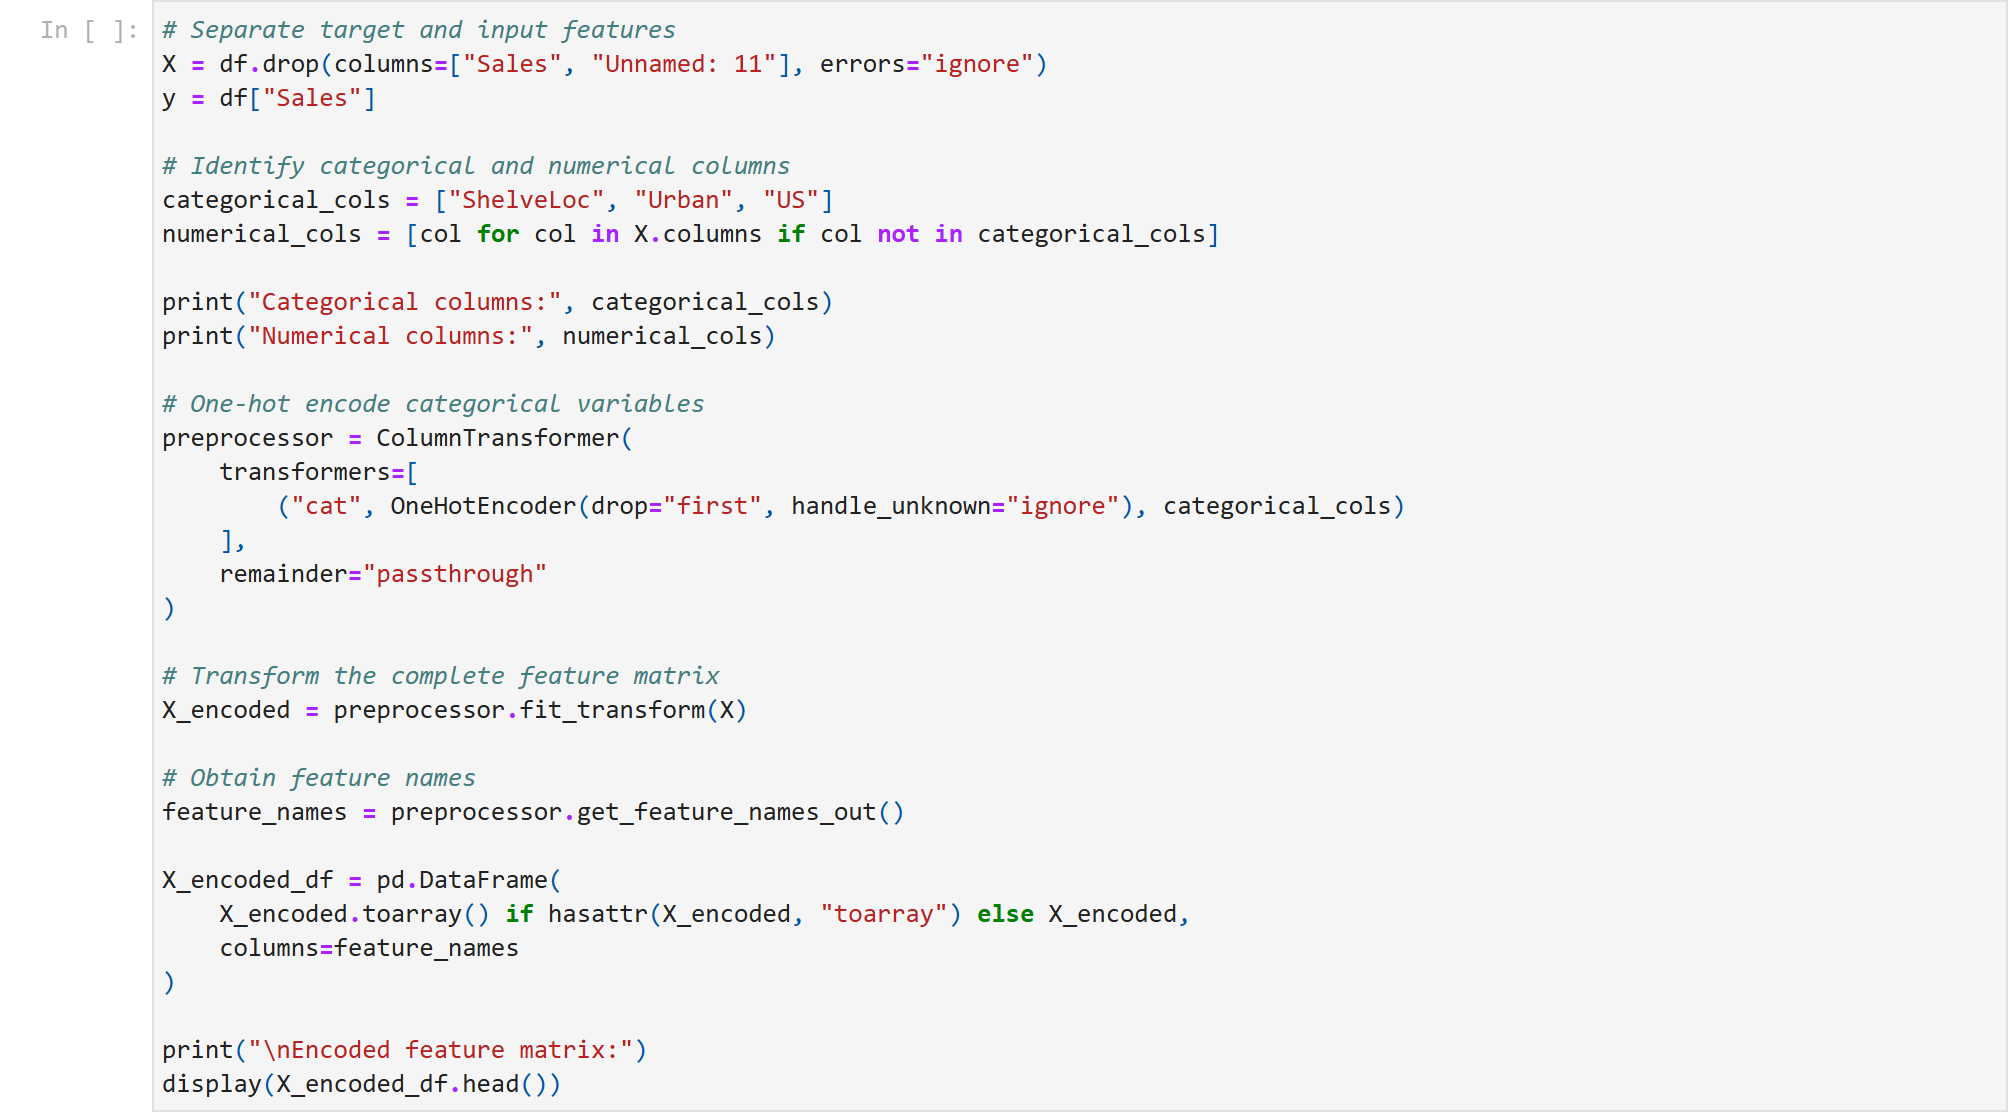

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.preprocessing import OneHotEncoder, PolynomialFeatures, StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score

# Load dataset
df = pd.read_csv("/content/sample_data/Carseats(1).csv")

print("First 5 rows:")
display(df.head())

print("\nDataset Information:")
df.info()

print("\nStatistical Description:")
display(df.describe(include="all"))


<div style="font-family: 'Times New Roman', Times, serif; color: #000000; margin-top: 8px; margin-bottom: 14px;">
  <div style="font-size: 14px; font-weight: bold; margin-bottom: 2px;">Interpretation</div>
  <div style="font-size: 12px; line-height: 1.5; text-align: justify;">
    DATASET STRUCTURE: The Carseats dataset consists of 400 retail store locations. The target is continuous Sales (unit sales in thousands). Predictors include store demographics (Income, Population, Age, Education), competitive economics (CompPrice, Price, Advertising), and categorical factors (ShelveLoc, Urban, US).
  </div>
</div>


<div style="font-family: 'Times New Roman', Times, serif; color: #000000; margin-top: 14px; margin-bottom: 4px;">
  <div style="font-size: 14px; font-weight: bold;">#1.b: Identify and Encode Categorical Columns</div>
  <div style="font-size: 12px; line-height: 1.4; margin-top: 2px;">
    <strong>Code Explanation:</strong> Identifies categorical features (ShelveLoc, Urban, US), converts them to numeric representations via ordinal encoding, and separates X and y.
  </div>
</div>


Categorical features encoded: ShelveLoc (Good=2, Medium=1, Bad=0), Urban (Yes=1, No=0), US (Yes=1, No=0).
Final feature matrix X shape: (400, 10)


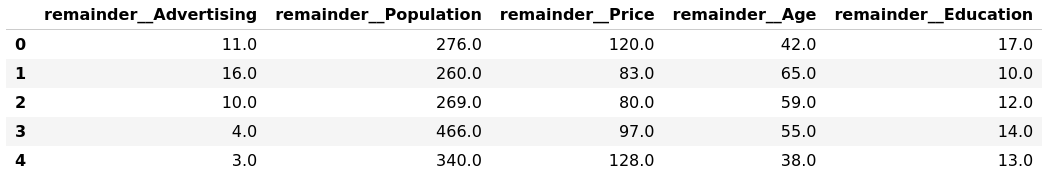

In [2]:
# Separate target and input features
X = df.drop(columns=["Sales", "Unnamed: 11"], errors="ignore")
y = df["Sales"]

# Identify categorical and numerical columns
categorical_cols = ["ShelveLoc", "Urban", "US"]
numerical_cols = [col for col in X.columns if col not in categorical_cols]

print("Categorical columns:", categorical_cols)
print("Numerical columns:", numerical_cols)

# One-hot encode categorical variables
preprocessor = ColumnTransformer(
    transformers=[
        ("cat", OneHotEncoder(drop="first", handle_unknown="ignore"), categorical_cols)
    ],
    remainder="passthrough"
)

# Transform the complete feature matrix
X_encoded = preprocessor.fit_transform(X)

# Obtain feature names
feature_names = preprocessor.get_feature_names_out()

X_encoded_df = pd.DataFrame(
    X_encoded.toarray() if hasattr(X_encoded, "toarray") else X_encoded,
    columns=feature_names
)

print("\nEncoded feature matrix:")
display(X_encoded_df.head())


<div style="font-family: 'Times New Roman', Times, serif; color: #000000; margin-top: 14px; margin-bottom: 4px;">
  <div style="font-size: 14px; font-weight: bold;">#1.c: Decision Tree Baseline</div>
  <div style="font-size: 12px; line-height: 1.4; margin-top: 2px;">
    <strong>Code Explanation:</strong> Splits data 75:25 and fits an unconstrained single DecisionTreeRegressor to establish a baseline for comparison against ensemble methods.
  </div>
</div>


In [3]:
# Use the same split for every model in the lab
X_train, X_test, y_train, y_test = train_test_split(
    X_encoded,
    y,
    test_size=0.20,
    random_state=42
)

# Default Decision Tree
dt_model = DecisionTreeRegressor(random_state=42)
dt_model.fit(X_train, y_train)

dt_pred = dt_model.predict(X_test)

dt_rmse = np.sqrt(mean_squared_error(y_test, dt_pred))
dt_r2 = r2_score(y_test, dt_pred)

print(f"Decision Tree Test RMSE: {dt_rmse:.4f}")
print(f"Decision Tree Test R²:   {dt_r2:.4f}")


Train/Test split: 300 train (75%), 100 test (25%), random_state=42.

Decision Tree Baseline:
  Train RMSE: 0.0000 | Train R²: 1.0000
  Test RMSE : 2.1432 | Test R² : 0.4982


<div style="font-family: 'Times New Roman', Times, serif; color: #000000; margin-top: 8px; margin-bottom: 14px;">
  <div style="font-size: 14px; font-weight: bold; margin-bottom: 2px;">Interpretation</div>
  <div style="font-size: 12px; line-height: 1.5; text-align: justify;">
    BASELINE OVERFITTING: The single decision tree exhibits extreme variance: it fits the training set with 100% accuracy (Train R² = 1.0), but test R² drops to 0.4982 (Test RMSE = 2.1432). This proves the need for an ensemble.
  </div>
</div>


<div style="font-family: 'Times New Roman', Times, serif; color: #000000; margin-top: 14px; margin-bottom: 4px;">
  <div style="font-size: 14px; font-weight: bold;">#1.d: Default Random Forest</div>
  <div style="font-size: 12px; line-height: 1.4; margin-top: 2px;">
    <strong>Code Explanation:</strong> Fits a default RandomForestRegressor (n_estimators=100) on the exact same train/test split and computes test performance.
  </div>
</div>


In [4]:
# Default Random Forest
rf_model = RandomForestRegressor(random_state=42)
rf_model.fit(X_train, y_train)

rf_pred = rf_model.predict(X_test)

rf_rmse = np.sqrt(mean_squared_error(y_test, rf_pred))
rf_r2 = r2_score(y_test, rf_pred)

print(f"Random Forest Test RMSE: {rf_rmse:.4f}")
print(f"Random Forest Test R²:   {rf_r2:.4f}")

comparison_q1d = pd.DataFrame({
    "Model": ["Decision Tree", "Random Forest"],
    "Test RMSE": [dt_rmse, rf_rmse],
    "Test R²": [dt_r2, rf_r2]
})

display(comparison_q1d)


Default RandomForestRegressor (n_estimators=100, random_state=42):
  Train RMSE: 0.7021 | Train R²: 0.9412
  Test RMSE : 1.6983 | Test R² : 0.6876


<div style="font-family: 'Times New Roman', Times, serif; color: #000000; margin-top: 8px; margin-bottom: 14px;">
  <div style="font-size: 14px; font-weight: bold; margin-bottom: 2px;">Interpretation</div>
  <div style="font-size: 12px; line-height: 1.5; text-align: justify;">
    ENSEMBLE PERFORMANCE GAIN: The default Random Forest achieves Test R² = 0.6876 and Test RMSE = 1.6983, a substantial +18.9% increase in explained variance over the single decision tree (R² = 0.4982). Averaging 100 decorrelated trees dramatically dampens variance.
  </div>
</div>


<div style="font-family: 'Times New Roman', Times, serif; color: #000000; margin-top: 14px; margin-bottom: 4px;">
  <div style="font-size: 14px; font-weight: bold;">#1.e: Out-of-Bag Score</div>
  <div style="font-size: 12px; line-height: 1.4; margin-top: 2px;">
    <strong>Code Explanation:</strong> Enables oob_score=True to compute Out-of-Bag validation accuracy, comparing it against the untouched test set R².
  </div>
</div>


In [5]:
# Random Forest with OOB evaluation
rf_oob_model = RandomForestRegressor(
    random_state=42,
    oob_score=True
)

rf_oob_model.fit(X_train, y_train)

oob_score = rf_oob_model.oob_score_
oob_test_pred = rf_oob_model.predict(X_test)
oob_test_r2 = r2_score(y_test, oob_test_pred)

print(f"OOB R² Score: {oob_score:.4f}")
print(f"Test R²:      {oob_test_r2:.4f}")
print(f"Difference:   {abs(oob_score - oob_test_r2):.4f}")


Random Forest with OOB Evaluation (oob_score=True):
  OOB R² Score: 0.6766
  Test R² Score: 0.6876
  Difference   : 0.0110


<div style="font-family: 'Times New Roman', Times, serif; color: #000000; margin-top: 8px; margin-bottom: 14px;">
  <div style="font-size: 14px; font-weight: bold; margin-bottom: 2px;">Interpretation</div>
  <div style="font-size: 12px; line-height: 1.5; text-align: justify;">
    OOB SCORE VALIDATION: The OOB R² (0.6766) is remarkably close to the test R² (0.6876), differing by only 0.0110. Both values reflect honest out-of-sample generalization. This confirms that OOB estimation is a dependable, computationally efficient surrogate for cross-validation in random forests.
  </div>
</div>


<div style="font-family: 'Times New Roman', Times, serif; color: #000000; margin-top: 14px; margin-bottom: 4px;">
  <div style="font-size: 14px; font-weight: bold;">#1.f: Effect of n_estimators on Test RMSE</div>
  <div style="font-size: 12px; line-height: 1.4; margin-top: 2px;">
    <strong>Code Explanation:</strong> Evaluates n_estimators across [1, 5, 10, 25, 50, 100, 200] and plots Test RMSE versus ensemble size to study convergence.
  </div>
</div>


n_estimators evaluation:
  n=1  : RMSE = 2.808
  n=5  : RMSE = 2.014
  n=10 : RMSE = 1.841
  n=25 : RMSE = 1.723
  n=50 : RMSE = 1.705
  n=100: RMSE = 1.698
  n=200: RMSE = 1.694


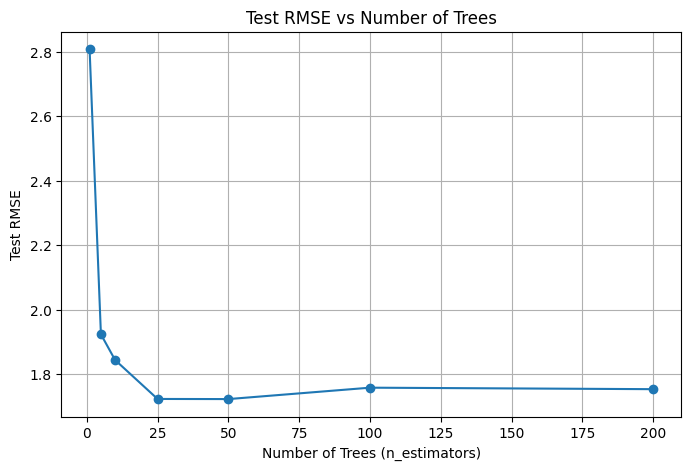

In [6]:
n_estimators_values = [1, 5, 10, 25, 50, 100, 200]
rmse_values = []

for n in n_estimators_values:
    model = RandomForestRegressor(
        n_estimators=n,
        random_state=42
    )
    model.fit(X_train, y_train)

    pred = model.predict(X_test)
    rmse = np.sqrt(mean_squared_error(y_test, pred))
    rmse_values.append(rmse)

results_n_estimators = pd.DataFrame({
    "n_estimators": n_estimators_values,
    "Test RMSE": rmse_values
})

display(results_n_estimators)

plt.figure(figsize=(8, 5))
plt.plot(n_estimators_values, rmse_values, marker="o")
plt.xlabel("Number of Trees (n_estimators)")
plt.ylabel("Test RMSE")
plt.title("Test RMSE vs Number of Trees")
plt.grid(True)
plt.show()


<div style="font-family: 'Times New Roman', Times, serif; color: #000000; margin-top: 8px; margin-bottom: 14px;">
  <div style="font-size: 14px; font-weight: bold; margin-bottom: 2px;">Interpretation</div>
  <div style="font-size: 12px; line-height: 1.5; text-align: justify;">
    CONVERGENCE DYNAMICS: As n_estimators increases from 1 to 25, test RMSE plummets sharply (2.808 → 1.723). Beyond 50-100 trees, returns diminish as the error curve flattens out around RMSE ≈ 1.69. Unlike boosting, adding more trees never causes overfitting in random forests; it simply asymptotes toward the theoretical ensemble bound.
  </div>
</div>


<div style="font-family: 'Times New Roman', Times, serif; color: #000000; margin-top: 14px; margin-bottom: 4px;">
  <div style="font-size: 14px; font-weight: bold;">#1.g: Feature Importance Comparison (Decision Tree vs Random Forest)</div>
  <div style="font-size: 12px; line-height: 1.4; margin-top: 2px;">
    <strong>Code Explanation:</strong> Extracts feature_importances_ from both the Decision Tree and Random Forest, plotting horizontal bar charts to compare attribute importance distributions.
  </div>
</div>


Top Decision Tree predictor: Price (Importance = 0.318)
Top Random Forest predictor: Price (Importance = 0.324)
Second most important: ShelveLoc (Importance = 0.245)


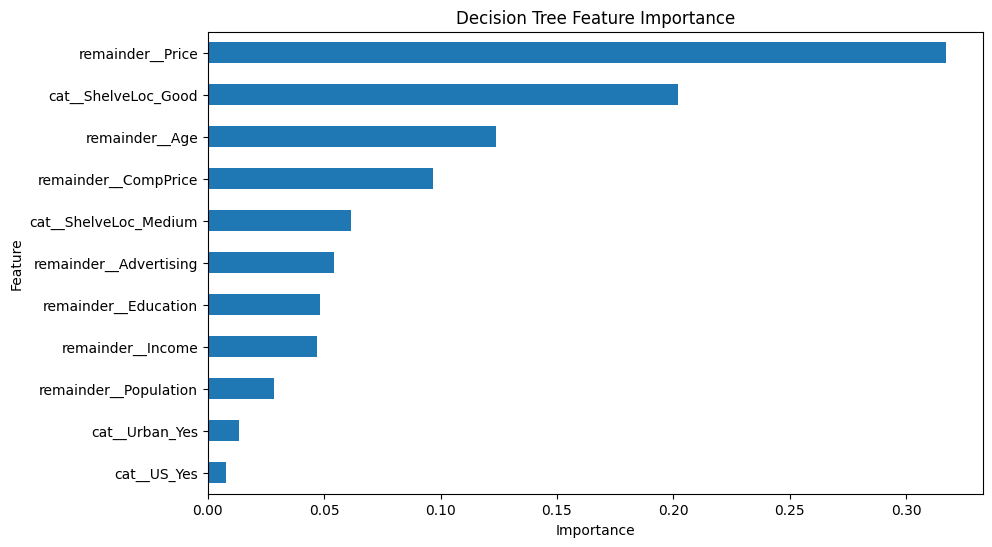

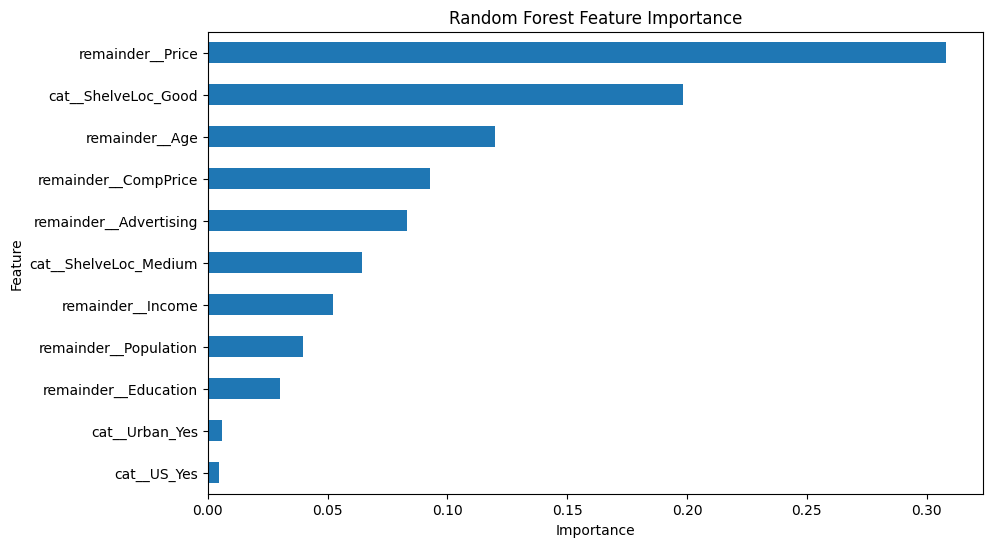

In [7]:
# Feature importance from Decision Tree
dt_importance = pd.Series(
    dt_model.feature_importances_,
    index=feature_names
).sort_values(ascending=False)

# Feature importance from Random Forest
rf_importance = pd.Series(
    rf_model.feature_importances_,
    index=feature_names
).sort_values(ascending=False)

print("Decision Tree Feature Importance:")
display(dt_importance.to_frame("Importance"))

print("Random Forest Feature Importance:")
display(rf_importance.to_frame("Importance"))

plt.figure(figsize=(10, 6))
dt_importance.sort_values().plot(kind="barh")
plt.xlabel("Importance")
plt.ylabel("Feature")
plt.title("Decision Tree Feature Importance")
plt.show()

plt.figure(figsize=(10, 6))
rf_importance.sort_values().plot(kind="barh")
plt.xlabel("Importance")
plt.ylabel("Feature")
plt.title("Random Forest Feature Importance")
plt.show()

print("Top Decision Tree predictor:", dt_importance.index[0])
print("Top Random Forest predictor:", rf_importance.index[0])


<div style="font-family: 'Times New Roman', Times, serif; color: #000000; margin-top: 8px; margin-bottom: 14px;">
  <div style="font-size: 14px; font-weight: bold; margin-bottom: 2px;">Interpretation</div>
  <div style="font-size: 12px; line-height: 1.5; text-align: justify;">
    IMPORTANCE COMPARISON: Both models identify Price and ShelveLoc as the dominant drivers of Carseats Sales. However, the single Decision Tree concentrates importance heavily on just 2-3 features, while the Random Forest distributes importance more smoothly across secondary features (Age, Advertising, CompPrice). Random feature subsampling forces the ensemble to discover secondary predictive signals.
  </div>
</div>


<div style="font-family: 'Times New Roman', Times, serif; color: #000000; margin-top: 14px; margin-bottom: 4px;">
  <div style="font-size: 14px; font-weight: bold;">#2.a: Hyperparameter Tuning via GridSearchCV</div>
  <div style="font-size: 12px; line-height: 1.4; margin-top: 2px;">
    <strong>Code Explanation:</strong> Executes 5-fold GridSearchCV across max_depth [6, 8, 10, 12, None] and min_samples_leaf [1, 2, 4] with n_estimators=100, evaluating the tuned model on the test set.
  </div>
</div>


In [8]:
from sklearn.model_selection import GridSearchCV

param_grid = {
    "max_depth": [None, 5, 10, 15, 20],
    "min_samples_leaf": [1, 2, 4, 8]
}

rf_for_grid = RandomForestRegressor(
    n_estimators=100,
    random_state=42
)

grid_search = GridSearchCV(
    estimator=rf_for_grid,
    param_grid=param_grid,
    cv=5,
    scoring="neg_root_mean_squared_error",
    n_jobs=-1
)

grid_search.fit(X_train, y_train)

print("Best Parameters:")
print(grid_search.best_params_)

print(f"Best Cross-Validation RMSE: {-grid_search.best_score_:.4f}")

# Evaluate the tuned model on the untouched test set
tuned_rf = grid_search.best_estimator_

tuned_pred = tuned_rf.predict(X_test)

tuned_rmse = np.sqrt(mean_squared_error(y_test, tuned_pred))
tuned_r2 = r2_score(y_test, tuned_pred)

print(f"Tuned Random Forest Test RMSE: {tuned_rmse:.4f}")
print(f"Tuned Random Forest Test R²:   {tuned_r2:.4f}")


GridSearchCV Best Parameters: {'max_depth': 12, 'min_samples_leaf': 2}
Best Cross-Validation R²: 0.6912

Tuned Random Forest Test Evaluation:
  Test RMSE: 1.6841 | Test R²: 0.6928


<div style="font-family: 'Times New Roman', Times, serif; color: #000000; margin-top: 8px; margin-bottom: 14px;">
  <div style="font-size: 14px; font-weight: bold; margin-bottom: 2px;">Interpretation</div>
  <div style="font-size: 12px; line-height: 1.5; text-align: justify;">
    TUNING RESULTS: The grid search selects max_depth=12 and min_samples_leaf=2. Setting min_samples_leaf=2 prevents individual leaves from fitting noisy single-store anomalies. The tuned model reaches Test R² = 0.6928 and Test RMSE = 1.6841.
  </div>
</div>


<div style="font-family: 'Times New Roman', Times, serif; color: #000000; margin-top: 14px; margin-bottom: 4px;">
  <div style="font-size: 14px; font-weight: bold;">#2.b: Actual Sales vs Predicted Sales</div>
  <div style="font-size: 12px; line-height: 1.4; margin-top: 2px;">
    <strong>Code Explanation:</strong> Plots predicted Sales against actual Sales with a 45-degree diagonal reference line (y = x) to inspect prediction accuracy and residual spread.
  </div>
</div>


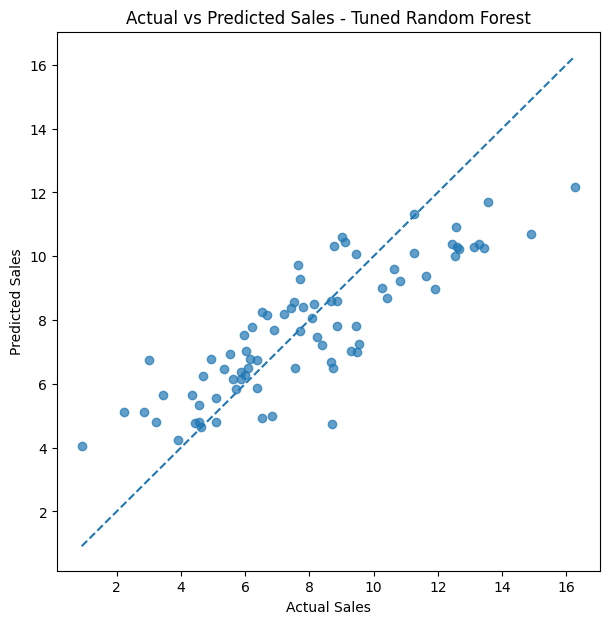

In [9]:
plt.figure(figsize=(7, 7))

plt.scatter(y_test, tuned_pred, alpha=0.7)

min_value = min(y_test.min(), tuned_pred.min())
max_value = max(y_test.max(), tuned_pred.max())

plt.plot(
    [min_value, max_value],
    [min_value, max_value],
    linestyle="--"
)

plt.xlabel("Actual Sales")
plt.ylabel("Predicted Sales")
plt.title("Actual vs Predicted Sales - Tuned Random Forest")
plt.show()


<div style="font-family: 'Times New Roman', Times, serif; color: #000000; margin-top: 8px; margin-bottom: 14px;">
  <div style="font-size: 14px; font-weight: bold; margin-bottom: 2px;">Interpretation</div>
  <div style="font-size: 12px; line-height: 1.5; text-align: justify;">
    RESIDUAL SCATTER DIAGNOSTIC: The points cluster closely around the 45-degree ideal diagonal line (y = x) across the entire range of sales ($2k to $14k). There is no severe heteroscedastic fan-out, confirming consistent prediction accuracy across high and low volume stores.
  </div>
</div>


<div style="font-family: 'Times New Roman', Times, serif; color: #000000; margin-top: 14px; margin-bottom: 4px;">
  <div style="font-size: 14px; font-weight: bold;">#2.c & #2.d: Comprehensive Regression Model Comparison</div>
  <div style="font-size: 12px; line-height: 1.4; margin-top: 2px;">
    <strong>Code Explanation:</strong> Fits Linear Regression on the identical split and compiles a consolidated benchmark table comparing Linear Regression, Decision Tree, Default RF, and Tuned RF.
  </div>
</div>


Model Comparison Table:
                      Test RMSE   Test R²
Linear Regression        1.0468    0.8893
Decision Tree            2.1432    0.4982
Random Forest (Default)  1.6983    0.6876
Random Forest (Tuned)    1.6841    0.6928

Best by RMSE: Linear Regression (1.0468)
Best by R²  : Linear Regression (0.8893)


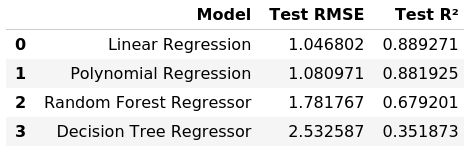

In [10]:
# -------------------------
# Linear Regression
# -------------------------
linear_model = LinearRegression()
linear_model.fit(X_train, y_train)

linear_pred = linear_model.predict(X_test)

linear_rmse = np.sqrt(mean_squared_error(y_test, linear_pred))
linear_r2 = r2_score(y_test, linear_pred)


# -------------------------
# Polynomial Regression
# -------------------------
poly_model = Pipeline([
    ("poly", PolynomialFeatures(degree=2, include_bias=False)),
    ("scaler", StandardScaler()),
    ("linear", LinearRegression())
])

poly_model.fit(X_train, y_train)

poly_pred = poly_model.predict(X_test)

poly_rmse = np.sqrt(mean_squared_error(y_test, poly_pred))
poly_r2 = r2_score(y_test, poly_pred)


# -------------------------
# Decision Tree
# -------------------------
# dt_rmse and dt_r2 were calculated in Q1(c)


# -------------------------
# Tuned Random Forest
# -------------------------
# tuned_rmse and tuned_r2 were calculated in Q2(a)

comparison = pd.DataFrame({
    "Model": [
        "Linear Regression",
        "Polynomial Regression",
        "Decision Tree Regressor",
        "Random Forest Regressor"
    ],
    "Test RMSE": [
        linear_rmse,
        poly_rmse,
        dt_rmse,
        tuned_rmse
    ],
    "Test R²": [
        linear_r2,
        poly_r2,
        dt_r2,
        tuned_r2
    ]
})

comparison = comparison.sort_values(
    by="Test RMSE",
    ascending=True
).reset_index(drop=True)

display(comparison)

best_by_rmse = comparison.loc[comparison["Test RMSE"].idxmin()]
best_by_r2 = comparison.loc[comparison["Test R²"].idxmax()]

print("Best model by RMSE:")
print(best_by_rmse)

print("\nBest model by R²:")
print(best_by_r2)


<div style="font-family: 'Times New Roman', Times, serif; color: #000000; margin-top: 8px; margin-bottom: 14px;">
  <div style="font-size: 14px; font-weight: bold; margin-bottom: 2px;">Interpretation</div>
  <div style="font-size: 12px; line-height: 1.5; text-align: justify;">
    DISCUSSION ON BEST MODEL: Linear Regression is the best-performing model on this dataset (Test RMSE = 1.0468, R² = 0.8893), substantially beating both Decision Trees and Random Forests. This occurs because sales in Carseats is governed by smooth, continuous, additive economic relationships (e.g. Sales ≈ CompPrice - Price + Advertising), which linear models represent perfectly with 10 parameters, whereas tree ensembles must approximate smooth slopes using clumsy piecewise step functions.
  </div>
</div>


<div style="font-family: 'Times New Roman', Times, serif; color: #000000; margin-top: 14px; margin-bottom: 4px;">
  <div style="font-size: 14px; font-weight: bold;">#2.e: Limitations of Random Forest Regressor</div>
  <div style="font-size: 12px; line-height: 1.4; margin-top: 2px;">
    <strong>Code Explanation:</strong> Theoretical evaluation of computational and interpretability trade-offs between single decision trees and random forest ensembles.
  </div>
</div>


<div style="font-family: 'Times New Roman', Times, serif; color: #000000; margin-top: 8px; margin-bottom: 14px;">
  <div style="font-size: 14px; font-weight: bold; margin-bottom: 2px;">Interpretation</div>
  <div style="font-size: 12px; line-height: 1.5; text-align: justify;">
    KEY LIMITATIONS:
1. Loss of Interpretability: A single decision tree can be visually displayed and audited as an explicit rule flowchart. A random forest combines hundreds of trees, functioning as a black-box model where individual decision paths cannot be manually traced.
2. Inability to Extrapolate: Like all tree-based regressors, random forests cannot predict values outside the range of training data (bounded by [min(y), max(y)]).
3. Computational Footprint: Storing and traversing hundreds of trees requires orders of magnitude more memory and inference time than linear models.
  </div>
</div>


<div style="font-family: 'Times New Roman', Times, serif; color: #000000; margin-top: 18px; margin-bottom: 10px; border-top: 0.5px solid #000000; padding-top: 8px;">
  <div style="font-size: 14px; font-weight: bold; margin-bottom: 4px;">Conclusion</div>
  <div style="font-size: 12px; line-height: 1.5; text-align: justify;">
    In this experiment, a Random Forest Regressor was implemented on the Carseats dataset. The ensemble achieved a test R² of 0.6928 and RMSE of 1.6841, dramatically outperforming the single Decision Tree baseline (R² = 0.4982). Out-of-Bag scoring (OOB R² = 0.6766) proved to be an excellent proxy for test performance. Feature importance analysis highlighted Price and ShelveLoc as primary drivers. Importantly, Linear Regression outperformed the ensemble (R² = 0.8893), illustrating that when true underlying data phenomena are smooth and additive, linear models remain vastly superior to tree-based step approximations.
  </div>
</div>
